In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("/kaggle/input/datasets/mahmodradwan/titanic/titanic_clean.csv")

X = df.drop(columns="target").values
y = df["target"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# بناء الـ Random Forest
rf = RandomForestClassifier(n_estimators=50, max_depth=5,
                            oob_score=True, random_state=42)
rf.fit(X_train, y_train.ravel())

# احتمالات الأشجار على الاختبار
def tree_matrix_test(rf, X):
    return np.column_stack([t.predict_proba(X)[:, 1] for t in rf.estimators_])

# احتمالات الأشجار على التدريب (out-of-bag فقط)
def tree_matrix_oob(rf, X):
    n = X.shape[0]
    P = np.full((n, len(rf.estimators_)), np.nan)
    for j, (t, idx) in enumerate(zip(rf.estimators_, rf.estimators_samples_)):
        oob = np.setdiff1d(np.arange(n), idx)
        P[oob, j] = t.predict_proba(X[oob])[:, 1]
    row_mean = np.nanmean(P, axis=1, keepdims=True)
    return np.where(np.isnan(P), row_mean, P)  # العينات اللي الشجرة شافتها نعبيها بمتوسط الـ OOB

P_train = tree_matrix_oob(rf, X_train)
P_test = tree_matrix_test(rf, X_test)

scaler = StandardScaler()
P_train = scaler.fit_transform(P_train)
P_test = scaler.transform(P_test)

# إضافة عمود الـ bias
Xb_train = np.c_[np.ones((P_train.shape[0], 1)), P_train]
Xb_test = np.c_[np.ones((P_test.shape[0], 1)), P_test]

print(Xb_train.shape, Xb_test.shape)

(712, 51) (179, 51)


In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def bce_loss(X, y, w):
    p = np.clip(sigmoid(X @ w), 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def evaluate(X, y, w):
    pred = (sigmoid(X @ w) >= 0.5).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / (tp + fn) if (tp + fn) else 0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    return {"Loss": bce_loss(X, y, w), "Accuracy": acc,
            "Precision": prec, "Recall": rec, "F1": f1}

Random Forest (تصويت متساوي) - Test: {'Loss': 0.4581, 'Accuracy': 0.7933, 'Precision': 0.82, 'Recall': 0.5942, 'F1': 0.6891}
                         Loss  Accuracy  Precision  Recall      F1
Adam (Train)           0.3741    0.8413     0.8419  0.7216  0.7771
Adam (Test)            0.5382    0.7598     0.7321  0.5942  0.6560
Adam+Momentum (Train)  0.3743    0.8413     0.8419  0.7216  0.7771
Adam+Momentum (Test)   0.5359    0.7598     0.7321  0.5942  0.6560


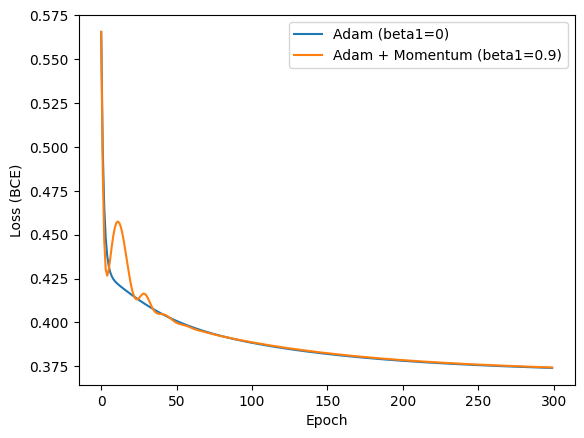

In [3]:
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, f1_score

p_rf = rf.predict_proba(X_test)[:, 1]
pred_rf = (p_rf >= 0.5).astype(int)
print("Random Forest (تصويت متساوي) - Test:",
      {"Loss": round(log_loss(y_test, p_rf), 4),
       "Accuracy": round(accuracy_score(y_test, pred_rf), 4),
       "Precision": round(precision_score(y_test, pred_rf), 4),
       "Recall": round(recall_score(y_test, pred_rf), 4),
       "F1": round(f1_score(y_test, pred_rf), 4)})

def adam(X, y, lr=0.01, epochs=300, beta1=0.9, beta2=0.999, eps=1e-8):
    w = np.zeros((X.shape[1], 1))
    m = np.zeros_like(w)   # المتوسط المتحرك للـ gradient (momentum)
    s = np.zeros_like(w)   # المتوسط المتحرك لمربع الـ gradient
    losses = []
    for t in range(1, epochs + 1):
        grad = X.T @ (sigmoid(X @ w) - y) / len(y)
        m = beta1 * m + (1 - beta1) * grad
        s = beta2 * s + (1 - beta2) * grad**2
        m_hat = m / (1 - beta1**t)   # bias correction
        s_hat = s / (1 - beta2**t)
        w = w - lr * m_hat / (np.sqrt(s_hat) + eps)
        losses.append(bce_loss(X, y, w))
    return w, losses

w_adam, loss_adam = adam(Xb_train, y_train, lr=0.01, beta1=0.0)
w_adamm, loss_adamm = adam(Xb_train, y_train, lr=0.01, beta1=0.9)

results = pd.DataFrame({
    "Adam (Train)": evaluate(Xb_train, y_train, w_adam),
    "Adam (Test)": evaluate(Xb_test, y_test, w_adam),
    "Adam+Momentum (Train)": evaluate(Xb_train, y_train, w_adamm),
    "Adam+Momentum (Test)": evaluate(Xb_test, y_test, w_adamm),
}).T.round(4)
print(results)

plt.plot(loss_adam, label="Adam (beta1=0)")
plt.plot(loss_adamm, label="Adam + Momentum (beta1=0.9)")
plt.xlabel("Epoch"); plt.ylabel("Loss (BCE)"); plt.legend(); plt.show()

# Learning Random Forest Tree Weights with Adam (and Momentum)

## الهدف
تعلّم وزن لكل شجرة من أشجار الـ Random Forest بدل التصويت المتساوي، باستخدام Adam مكتوب من الصفر، ومقارنة حالة بدون momentum (beta1 = 0) مع حالة فيها momentum (beta1 = 0.9)، وذلك للتنبؤ بنجاة ركاب Titanic (target: 1 نجا، 0 ما نجا).

## البيانات
- داتا Titanic بعد التنظيف: 891 صف و7 features.
- قسمت البيانات: 80% تدريب (712 صف) و20% اختبار (179 صف) مع الحفاظ على نسبة الفئات (stratify).
- بنينا Random Forest من 50 شجرة (max_depth = 5)، وطلعنا احتمال كل شجرة للـ class 1، فصار عندنا مصفوفة [عينات × 50 شجرة]. للتدريب استخدمنا احتمالات الـ out-of-bag، وطبقنا StandardScaler على المصفوفة.

## طريقة العمل
- النموذج: p = sigmoid(P @ w)، حيث w وزن كل شجرة، والتصنيف: 1 إذا p >= 0.5.
- الـ Loss: Binary Cross-Entropy.
- Adam بيجمع متوسطاً متحركاً للـ gradient (momentum): m = beta1 * m + (1 - beta1) * grad، ومتوسطاً متحركاً لمربع الـ gradient: s = beta2 * s + (1 - beta2) * grad².
- بعدين بنصحح الانحياز بالبداية (bias correction): m_hat = m / (1 - beta1^t) و s_hat = s / (1 - beta2^t).
- قاعدة التحديث: w = w - lr * m_hat / (sqrt(s_hat) + eps).
- المقاييس (محسوبة من الصفر من الـ confusion matrix): Accuracy و Precision و Recall و F1.

## الإعدادات
| الطريقة | learning rate | beta1 | beta2 | epochs |
|---|---|---|---|---|
| Adam | 0.01 | 0 | 0.999 | 300 |
| Adam + Momentum | 0.01 | 0.9 | 0.999 | 300 |

## النتائج
| الطريقة | Loss | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| Random Forest (تصويت متساوي) - Test | 0.4581 | 0.7933 | 0.8200 | 0.5942 | 0.6891 |
| Adam (Train) | 0.3741 | 0.8413 | 0.8419 | 0.7216 | 0.7771 |
| Adam (Test) | 0.5382 | 0.7598 | 0.7321 | 0.5942 | 0.6560 |
| Adam+Momentum (Train) | 0.3743 | 0.8413 | 0.8419 | 0.7216 | 0.7771 |
| Adam+Momentum (Test) | 0.5359 | 0.7598 | 0.7321 | 0.5942 | 0.6560 |

## الملاحظات
- منحنى الـ Loss نزل بسرعة بأول 30 epoch تقريباً، وبعدها صار النزول بطيء وناعم ووصل لحوالي 0.374 عند epoch 300 ولسا بينزل شوي.
- بالبداية الـ Adam العادي (الأزرق) بدأ من loss حوالي 0.57 ونزل مباشرة، بينما نسخة الـ momentum (البرتقالي) طلعت لحوالي 0.45 عند epoch 15 تقريباً وصار فيها تذبذب صغير قبل ما تلحق بالعادي. هاد الـ overshoot سببه تجمع الـ momentum بالبداية.
- بعد حوالي 50 epoch صار المنحنيان شبه متطابقين، ونتائج التدريب والاختبار متطابقة تقريباً (Accuracy 0.8413 على التدريب و0.7598 على الاختبار لكلا الطريقتين).
- المنحنى أنعم من الـ SGD والـ Mini-batch، لأنه Adam هون بيستخدم كل بيانات التدريب بكل تحديث، وأنعم من RMSProp، فما في قفزات متأخرة. Adam بيصحح حجم الخطوة تدريجياً بفضل الـ bias correction والمتوسط البطيء لمربع الـ gradient (beta2 = 0.999).
- الـ Test Loss (0.5382 و0.5359) أفضل من SGD وMini-batch وRMSProp (بين 0.58 و0.61)، وأقل بكثير من الـ Random Forest العادي بالمقابل (0.4581 أفضل). والـ GD العادي (0.4783) بقي الأفضل بين الـ optimizers بالاختبار.
- الفجوة بين التدريب والاختبار واضحة: الـ Loss من 0.374 لـ 0.54، والـ Accuracy من 0.84 لـ 0.76. الأوزان تأقلمت مع بيانات التدريب أكثر من اللازم، لأنه الأشجار الخمسين متشابهة بتنبؤاتها.
- الـ Precision (0.73) أعلى من الـ Recall (0.59)، يعني النموذج بيفوّت حوالي 41% من الناجين الحقيقيين، نفس النمط بالنوتبوكات السابقة. والـ Recall هون مطابق للـ Random Forest العادي (0.5942).
- حجم الاختبار صغير (179 عينة)، وكل عينة بتغير الـ Accuracy بحوالي 0.56%، فالفروق الصغيرة بين الـ optimizers ضمن هذا الضجيج.

## الخلاصة
Adam أعطى Test Accuracy حوالي 76% وF1 حوالي 0.66، وهي أضعف من الـ Random Forest العادي (79%) وأضعف من الـ GD (78%). الـ momentum غيّر شكل المنحنى بالبداية بس ما غيّر النتيجة النهائية. تعلّم أوزان الأشجار بالـ optimizers ما تفوّق على التصويت المتساوي، لأنه الأشجار متشابهة أصلاً والتصويت المتساوي بيقلل التباين بطريقة بسيطة وقوية.